# Can Predictive Uncertainty Flag Unreliable Classifications of Early-Stage Pancreatic Cancer?

**BME 304 Final Project** | Rosalyn Morin & Daniel Elsharkawy

This notebook goes through the analysis step by step. Run the cells **in order, from top to bottom**.

| Step | What it does |
|---|---|
| 1 | Imports and settings |
| 2 | Load the data |
| 3 | Select eligible samples (controls, benign disease, stage I–II PDAC) |
| 4 | Explore the data and check the log transformation |
| 5 | Define the model (log-transform, standardize, logistic regression) |
| 6 | Stratified 5-fold cross-validation with 200 bootstrap models per fold |
| 7 | Overall model performance |
| 8 | RQ1: Is bootstrap variability linked to errors, and does it flag errors better than distance to the threshold? |
| 9 | RQ2: Is the effect strongest for benign disease, especially chronic pancreatitis? |
| 10 | RQ3: What does each flagging approach cost? |
| 11 | RQ4: Calibration |
| 12 | Summary |

**Data:** S1 Table from Debernardi et al., *PLOS Medicine* (2020), doi: 10.1371/journal.pmed.1003489.

## Step 1: Imports and settings

If an import fails, uncomment the `%pip` line, run it once, then restart the kernel.

In [2]:
# %pip install pandas numpy scipy scikit-learn matplotlib

# the usual toolkit: data, math, plots, stats
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# sklearn pieces we need (same ones from the labs/lectures)
from sklearn.model_selection import StratifiedKFold   # CV that keeps group proportions equal
from sklearn.preprocessing import StandardScaler      # mean 0, SD 1 scaling
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample                    # used for bootstrap sampling
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, balanced_accuracy_score
from sklearn.calibration import calibration_curve

# newer sklearn warns that penalty=None is being renamed - same model, so we hide the warning
warnings.filterwarnings("ignore", category=FutureWarning)

# settings we use everywhere
SEED = 304                     # fixed seed -> same folds + same bootstraps every run
n_folds = 5                    # outer CV folds
Bootstrap_samples = 200        # bootstrap models per fold
FLAG_PROPORTIONS = np.round(np.arange(0, 0.55, 0.05), 2)   # flag 0%, 5%, ..., 50% of samples

# the same five predictors as PancRISK
features = ["age", "creatinine", "LYVE1", "REG1B", "TFF1"]
log_features = ["creatinine", "LYVE1", "REG1B", "TFF1"]   # concentrations are skewed, so we log them

plt.rcParams["font.size"] = 10   # keeps figure text >= 9 pt (course requirement)

# folders for saved figures and tables
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Step 2: Load the data

Debernardi et al 2020 data.csv is the dataset we are interested in analyzing, the code below responsibleg for opening that data.

In [3]:
# read the data (the paper's public S1 table)
raw = pd.read_csv ("Debernardi et al 2020 data.csv")

# quick look at the first few rows
raw.head()

,sample_id,patient_cohort,sample_origin,age,sex,diagnosis,stage,benign_sample_diagnosis,plasma_CA19_9,creatinine,LYVE1,REG1B,TFF1,REG1A
0,S1,Cohort1,BPTB,33,F,1,NaN,NaN,11.7,1.83222,0.893219,52.94884,654.282174,1262.000
1,S10,Cohort1,BPTB,81,F,1,NaN,NaN,NaN,0.97266,2.037585,94.46703,209.488250,228.407
2,S100,Cohort2,BPTB,51,M,1,NaN,NaN,7.0,0.78039,0.145589,102.36600,461.141000,NaN
3,S101,Cohort2,BPTB,61,M,1,NaN,NaN,8.0,0.70122,0.002805,60.57900,142.950000,NaN
4,S102,Cohort2,BPTB,62,M,1,NaN,NaN,9.0,0.21489,0.000860,65.54000,41.088000,NaN


### Match the column names

Cleaning: the left side is the name used in this notebook, and the right side is the column name in the file. If the check below says a column is missing, change the right-hand name to match the file.

In [4]:
# left = our short name, right = the column name in the file

COLUMN_NAMES = {
    "id": "sample_id",
    "cohort": "patient_cohort",
    "site": "sample_origin",
    "age": "age",
    "diagnosis": "diagnosis",                  # 1 = control, 2 = benign, 3 = PDAC
    "stage": "stage",
    "benign_dx": "benign_sample_diagnosis",
    "creatinine": "creatinine",
    "LYVE1": "LYVE1",
    "REG1B": "REG1B",
    "TFF1": "TFF1",
}

# stop early if a column we need isn't in the file
missing = [col for col in COLUMN_NAMES.values() if col not in raw.columns]
if missing:
    raise ValueError(f"These columns were not found in the file: {missing}. Update COLUMN_NAMES above.")

# rename to our short names
df = raw.rename(columns={file_name: our_name for our_name, file_name in COLUMN_NAMES.items()})
print("All columns found.")

All columns found.


## Step 3: Select eligible samples

We keep:
- all healthy controls (diagnosis = 1)
- all benign hepatobiliary disease samples (diagnosis = 2)
- PDAC samples (diagnosis = 3) only if they are **stage I–II**

The outcome is `y = 1` for early-stage PDAC and `y = 0` for everyone else.

Expected counts from our proposal: **493** eligible records, **102** cancers, **16** stage I.

In [5]:
# how many samples per group? (1 = control, 2 = benign, 3 = PDAC)
print(df["diagnosis"].value_counts().sort_index())

# how many PDAC samples at each stage (incl. missing)
print(df.loc[df["diagnosis"] == 3, "stage"].value_counts(dropna=False))

diagnosis
1    183
2    208
3    199
Name: count, dtype: int64
stage
III    76
IIB    68
IV     21
IB     12
IIA    11
II      7
IA      3
I       1
Name: count, dtype: int64


In [6]:
# "early" = stage I or II, including the sub-stages
early_stages = ["I", "IA", "IB", "II", "IIA", "IIB"]

# tidy the stage text so " iib" and "IIB" match
stage_clean = df["stage"].astype(str).str.strip().str.upper()

# True/False masks for each group we keep
is_control = df["diagnosis"] == 1
is_benign = df["diagnosis"] == 2
is_early_pdac = (df["diagnosis"] == 3) & (stage_clean.isin(early_stages))

# keep controls + benign + early PDAC; late/unstaged cancers are dropped (not relabeled)
data = df[is_control | is_benign | is_early_pdac].copy()
data["stage_clean"] = stage_clean[data.index]
data = data.reset_index(drop=True)

In [7]:
# outcome: 1 = early PDAC, 0 = control or benign
data["y"] = (data["diagnosis"] == 3).astype(int)

# readable group names for tables and plots
data["group"] = data["diagnosis"].map({1: "Control", 2: "Benign", 3: "PDAC I-II"})

# chronic pancreatitis = any benign label with "pancreatitis" in it
# (gives 119, same as the paper's chronic pancreatitis count)
benign_text = data["benign_dx"].astype(str).str.lower()
data["chronic_pancreatitis"] = (
    (data["diagnosis"] == 2)
    & (benign_text.str.contains("pancreatitis"))
)

### Check for missing values in the predictors

Our proposal found the five predictors complete for all 493 eligible records, so every count below should be 0.

In [8]:
predictors = ["age", "creatinine", "LYVE1", "REG1B", "TFF1"]

# missing values per predictor (want all 0 -> no imputation needed)
print(data[predictors].isna().sum())

# zero/negative concentrations would break the log (want all 0)
print(data[["creatinine", "LYVE1", "REG1B", "TFF1"]].le(0).sum())

age           0
creatinine    0
LYVE1         0
REG1B         0
TFF1          0
dtype: int64
creatinine    0
LYVE1         0
REG1B         0
TFF1          0
dtype: int64


### Cohort summary

These counts go into the Data section and Table 1 of the report.

In [9]:
# cohort numbers for the report (Methods 2.1 / Results 3.1)
print(f"Eligible records: {len(data)}")
print(data["group"].value_counts())
print()
print("Early PDAC by stage:")
print(data.loc[data["y"] == 1, "stage_clean"].value_counts())
print(f"Stage I (I, IA, IB): {data['stage_clean'].isin(['I', 'IA', 'IB']).sum()}")
print()
# ~21% cancers -> accuracy alone would be misleading
print(f"Cancer share: {data['y'].mean():.1%}")
print(f"Chronic pancreatitis (benign label contains 'pancreatitis'): {data['chronic_pancreatitis'].sum()}")
print(f"Other benign: {((data['group'] == 'Benign') & ~data['chronic_pancreatitis']).sum()}")
print()
# where samples were collected (all controls come from one site - a limitation)
print("Collection site by group:")
print(pd.crosstab(data["site"], data["group"]))

Eligible records: 493
group
Benign       208
Control      183
PDAC I-II    102
Name: count, dtype: int64

Early PDAC by stage:
stage_clean
IIB    68
IB     12
IIA    11
II      7
IA      3
I       1
Name: count, dtype: int64
Stage I (I, IA, IB): 16

Cancer share: 20.7%
Chronic pancreatitis (benign label contains 'pancreatitis'): 119
Other benign: 89

Collection site by group:
group  Benign  Control  PDAC I-II
site                             
BPTB      143      183         37
ESP         6        0          8
LIV        39        0         57
UCL        20        0          0


## Step 4: Explore the data

Biomarker concentrations are usually right-skewed. The log transformation should make them more symmetric, which suits logistic regression better.

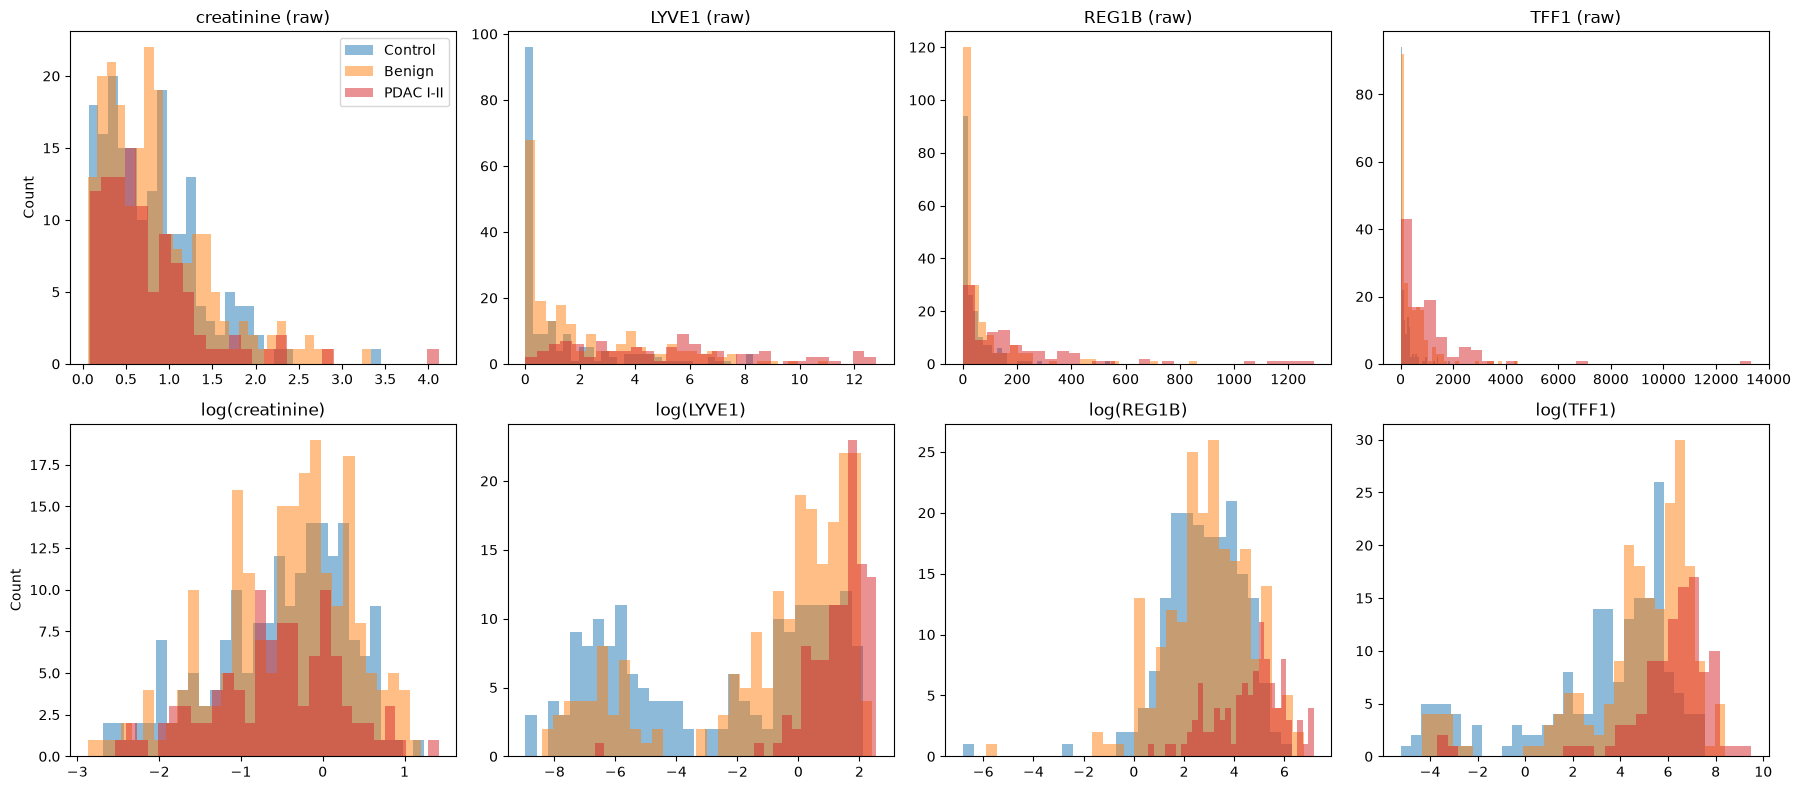

In [10]:
concentrations = ["creatinine", "LYVE1", "REG1B", "TFF1"]
groups = ["Control", "Benign", "PDAC I-II"]
colors = ["tab:blue", "tab:orange", "tab:red"]

# top row = raw values, bottom row = log values
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for col_i, col in enumerate(concentrations):
    for grp, color in zip(groups, colors):
        values = data.loc[data["group"] == grp, col]
        axes[0, col_i].hist(values, bins=30, alpha=0.5, color=color, label=grp)
        axes[1, col_i].hist(np.log(values), bins=30, alpha=0.5, color=color, label=grp)
    axes[0, col_i].set_title(f"{col} (raw)")
    axes[1, col_i].set_title(f"log({col})")

axes[0, 0].legend()
for ax in axes[:, 0]:
    ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("biomarker_distributions.png", dpi=200)
plt.show()

In [11]:
# median of each predictor by group (PDAC should be higher for the biomarkers)
data.groupby("group")[features].median().round(3)

,age,creatinine,LYVE1,REG1B,TFF1
group,,,,,
Benign,54.0,0.746,1.212,20.155,210.213
Control,57.0,0.713,0.146,17.583,59.793
PDAC I-II,68.0,0.594,4.746,127.901,704.663


## Step 5: Define the model

1. **Log-transform** the four concentrations with the natural log (age is left as is). All concentrations are positive (checked in Step 3). The log is applied to each sample on its own and does not learn anything from the other samples, so it is safe to do once before splitting.
2. **Standardize** all five predictors with `StandardScaler`. The scaler *does* learn something (the mean and standard deviation), so it is fit on the training data only (`fit_transform`) and then applied to the test data (`transform`). This prevents data leakage.
3. Fit a **logistic regression with no regularization** (`penalty=None`), like the published PancRISK model.

`fit_model` does steps 2 and 3 on a training set, and `predict_prob` uses the fitted scaler and model to predict the probability of cancer for new samples.

In [12]:
# natural log of the 4 concentrations (age stays as is)
# safe to do before splitting: log uses only each sample's own value
for col in log_features:
    data["log_" + col] = np.log(data[col])

model_features = ["age", "log_creatinine", "log_LYVE1", "log_REG1B", "log_TFF1"]


def fit_model(X_train, y_train):
    # scaler learns mean/SD from the TRAINING data only (no leakage)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # plain logistic regression, no regularization (like PancRISK)
    model = LogisticRegression(penalty=None, max_iter=5000)
    model.fit(X_train_scaled, y_train)
    return scaler, model


def predict_prob(scaler, model, X):
    # scale new data with the TRAINING scaler, then get P(cancer)
    X_scaled = scaler.transform(X)
    return model.predict_proba(X_scaled)[:, 1]

### Choosing the classification threshold

The threshold is chosen **using only the training fold**:
1. Run an inner 5-fold cross-validation on the training fold to get out-of-sample probabilities.
2. Pick the threshold that maximizes **Youden's J** (sensitivity + specificity − 1).

This keeps the test fold completely unseen.

In [13]:
def choose_threshold(X_train, y_train, seed):
    # inner 5-fold CV inside the training fold -> the test fold never helps pick the threshold
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    p_inner = np.zeros(len(y_train))

    # each training sample gets a probability from a model that didn't see it
    for inner_train, inner_val in inner_cv.split(X_train, y_train):
        scaler, model = fit_model(X_train[inner_train], y_train[inner_train])
        p_inner[inner_val] = predict_prob(scaler, model, X_train[inner_val])

    # pick the cutoff with the best Youden's J (sensitivity + specificity - 1)
    fpr, tpr, thresholds = roc_curve(y_train, p_inner)
    youden_j = tpr - fpr
    return thresholds[np.argmax(youden_j)]

## Step 6: Cross-validation with bootstrap uncertainty

For each of the 5 outer folds:
1. Fit the main model on the training fold and predict the held-out test fold.
2. Choose the threshold from the training fold (Step 5).
3. Fit **200 bootstrap models**, each on a resample of the training fold drawn **with replacement** (`resample(..., replace=True)`), and predict the test fold with each.
4. For each test sample, record:
   - `p`: the main model's predicted probability of cancer
   - `boot_sd`: the **standard deviation** of the 200 bootstrap predictions (our uncertainty measure)
   - `dist_to_threshold`: how far `p` is from the threshold (the simple baseline)

The folds are stratified by **diagnosis group** (control / benign / PDAC), so every fold has the same mix of all three.

This takes about a minute or two.

In [14]:
# X = 493 samples x 5 predictors, y = 0/1 labels
X = data[model_features].values
y = data["y"].values

# split by group (control/benign/PDAC) so every fold has the same mix
outer_cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, data["group"]), start=1):
    X_train, y_train = X[train_idx], y[train_idx]
    X_test = X[test_idx]

    # 1. main model on the full training fold -> probabilities for the test fold
    scaler, model = fit_model(X_train, y_train)
    p_test = predict_prob(scaler, model, X_test)

    # 2. threshold picked from the training fold only
    threshold = choose_threshold(X_train, y_train, seed=SEED + fold)

    # 3. 200 bootstrap models: resample training rows WITH replacement, refit, predict the test fold
    boot_preds = np.zeros((Bootstrap_samples, len(test_idx)))   # rows = bootstrap models, cols = test samples
    for b in range(Bootstrap_samples):
        X_boot, y_boot = resample(X_train, y_train, replace=True,
                                  random_state=SEED * 1000 + fold * Bootstrap_samples + b)   # new seed each time
        boot_scaler, boot_model = fit_model(X_boot, y_boot)
        boot_preds[b] = predict_prob(boot_scaler, boot_model, X_test)

    # 4. save what we need for each test sample
    fold_df = data.iloc[test_idx][["id", "group", "chronic_pancreatitis", "y"]].copy()
    fold_df["fold"] = fold
    fold_df["p"] = p_test                                     # main model's P(cancer)
    fold_df["threshold"] = threshold
    fold_df["pred"] = (p_test >= threshold).astype(int)      # predicted class
    fold_df["boot_mean"] = boot_preds.mean(axis=0)
    fold_df["boot_sd"] = boot_preds.std(axis=0, ddof=1)      # our uncertainty score
    fold_df["dist_to_threshold"] = np.abs(p_test - threshold) # simple baseline (small = borderline)
    fold_results.append(fold_df)

    print(f"Fold {fold}: {len(train_idx)} train, {len(test_idx)} test, "
          f"{y[test_idx].sum()} cancers in test, threshold = {threshold:.3f}")

# put the 5 folds back together in the original row order
results = pd.concat(fold_results).sort_index()
results["error"] = (results["pred"] != results["y"]).astype(int)   # 1 = model got it wrong

results.to_csv("results/cv_predictions.csv", index=False)
results.head()

Fold 1: 394 train, 99 test, 20 cancers in test, threshold = 0.281
Fold 2: 394 train, 99 test, 21 cancers in test, threshold = 0.191
Fold 3: 394 train, 99 test, 21 cancers in test, threshold = 0.244
Fold 4: 395 train, 98 test, 20 cancers in test, threshold = 0.238
Fold 5: 395 train, 98 test, 20 cancers in test, threshold = 0.216


,id,group,chronic_pancreatitis,y,fold,p,threshold,pred,boot_mean,boot_sd,dist_to_threshold,error
0,S1,Control,False,0,2,0.012126,0.191185,0,0.011012,0.005868,0.179059,0
1,S10,Control,False,0,5,0.502000,0.215951,1,0.494587,0.075186,0.286049,1
2,S100,Control,False,0,4,0.032724,0.237842,0,0.032557,0.016310,0.205118,0
3,S101,Control,False,0,2,0.002791,0.191185,0,0.003821,0.004950,0.188394,0
4,S102,Control,False,0,5,0.004791,0.215951,0,0.008767,0.014939,0.211160,0


## Step 7: Overall model performance

Metrics are calculated on each held-out fold, then summarized as **mean ± SD across the 5 folds**.

In [15]:
# metrics for each held-out fold
rows = []
for fold, fdf in results.groupby("fold"):
    tn, fp, fn, tp = confusion_matrix(fdf["y"], fdf["pred"]).ravel()
    rows.append({
        "Fold": fold,
        "AUROC": roc_auc_score(fdf["y"], fdf["p"]),          # uses probabilities, not classes
        "Sensitivity": tp / (tp + fn),                         # cancers caught
        "Specificity": tn / (tn + fp),                         # non-cancers correctly cleared
        "Balanced accuracy": balanced_accuracy_score(fdf["y"], fdf["pred"]),
        "Threshold": fdf["threshold"].iloc[0],
    })

fold_metrics = pd.DataFrame(rows)
fold_metrics.to_csv("results/per_fold_metrics.csv", index=False)
print(fold_metrics.round(3).to_string(index=False))
print()
# mean +/- SD across folds (what goes in Table 1)
print("Mean ± SD across the 5 folds:")
for col in ["AUROC", "Sensitivity", "Specificity", "Balanced accuracy", "Threshold"]:
    print(f"  {col}: {fold_metrics[col].mean():.3f} ± {fold_metrics[col].std():.3f}")

 Fold  AUROC  Sensitivity  Specificity  Balanced accuracy  Threshold
    1  0.868        0.700        0.835              0.768      0.281
    2  0.924        1.000        0.705              0.853      0.191
    3  0.906        0.857        0.859              0.858      0.244
    4  0.915        0.850        0.808              0.829      0.238
    5  0.908        0.800        0.859              0.829      0.216

Mean ± SD across the 5 folds:
  AUROC: 0.904 ± 0.022
  Sensitivity: 0.841 ± 0.109
  Specificity: 0.813 ± 0.064
  Balanced accuracy: 0.827 ± 0.036
  Threshold: 0.234 ± 0.033


Pooled held-out predictions (n = 493)
  TP = 86, FN = 16, TN = 318, FP = 73
  Total errors = 89 (18.1%): 73 false positives, 16 false negatives
  Pooled AUROC = 0.901


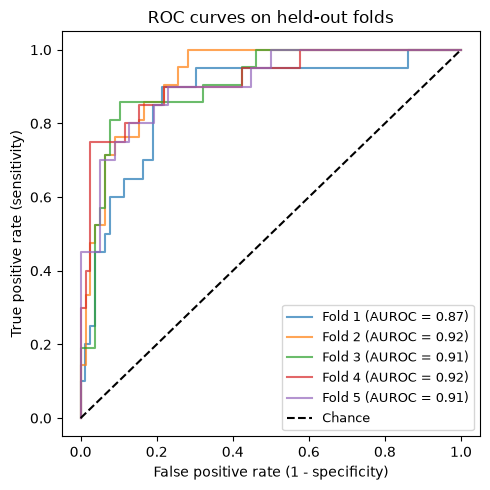

In [16]:
# confusion matrix over all 493 held-out predictions
tn, fp, fn, tp = confusion_matrix(results["y"], results["pred"]).ravel()
print(f"Pooled held-out predictions (n = {len(results)})")
print(f"  TP = {tp}, FN = {fn}, TN = {tn}, FP = {fp}")
print(f"  Total errors = {fp + fn} ({(fp + fn) / len(results):.1%}): {fp} false positives, {fn} false negatives")
print(f"  Pooled AUROC = {roc_auc_score(results['y'], results['p']):.3f}")

# one ROC curve per fold
fig, ax = plt.subplots(figsize=(5, 5))
for fold, fdf in results.groupby("fold"):
    fpr, tpr, _ = roc_curve(fdf["y"], fdf["p"])
    ax.plot(fpr, tpr, alpha=0.7, label=f"Fold {fold} (AUROC = {roc_auc_score(fdf['y'], fdf['p']):.2f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves on held-out folds")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig("figures/roc_curves.png", dpi=200)
plt.show()

### AUROC by comparison

These AUROCs use all held-out predictions pooled together, restricted to one negative group at a time. Our model is trained on the combined task (controls + benign vs. early PDAC), so these numbers are **not** a reproduction of PancRISK. Check the exact model and stage grouping in Debernardi et al. before placing the paper's values next to ours.

In [17]:
# AUROC with one negative group at a time vs. early PDAC (like the paper's comparisons)
is_pdac = results["group"] == "PDAC I-II"
comparisons = {
    "Controls vs. PDAC I-II": results["group"] == "Control",
    "Benign vs. PDAC I-II": results["group"] == "Benign",
    "Chronic pancreatitis vs. PDAC I-II": results["chronic_pancreatitis"],
}

rows = []
for name, is_negative in comparisons.items():
    subset = results[is_negative | is_pdac]     # only that negative group + all PDAC
    rows.append({"Comparison": name,
                 "Negatives": int(is_negative.sum()),
                 "PDAC I-II": int(is_pdac.sum()),
                 "AUROC": round(roc_auc_score(subset["y"], subset["p"]), 3)})
comparison_auc = pd.DataFrame(rows)
print(comparison_auc.to_string(index=False))

                        Comparison  Negatives  PDAC I-II  AUROC
            Controls vs. PDAC I-II        183        102  0.940
              Benign vs. PDAC I-II        208        102  0.866
Chronic pancreatitis vs. PDAC I-II        119        102  0.858


## Step 8: RQ1 — Is bootstrap variability linked to errors?

**RQ1.** Are incorrect classifications associated with higher bootstrap variability, and when both approaches set aside the same proportion of samples, does flagging by bootstrap variability produce a lower error rate among the remaining predictions than flagging by distance from the decision threshold?

### 8a. Do wrong predictions have higher bootstrap variability?

- **Mann–Whitney U test** (one-sided): is `boot_sd` higher for wrong predictions than correct ones? We use a non-parametric test because uncertainty values are usually skewed.
- **AUROC for error detection**: how well each measure ranks wrong predictions above correct ones (0.5 = no better than chance). For distance to the threshold, a *smaller* distance means *less* sure, so we use the negative distance.

In [18]:
# tag every prediction as TP / FP / TN / FN (used for the rest of the notebook)
results["outcome"] = "TN"
results.loc[(results["y"] == 1) & (results["pred"] == 1), "outcome"] = "TP"
results.loc[(results["y"] == 0) & (results["pred"] == 1), "outcome"] = "FP"
results.loc[(results["y"] == 1) & (results["pred"] == 0), "outcome"] = "FN"

# bootstrap SD for wrong vs. right predictions
wrong = results["error"] == 1
sd_wrong = results.loc[wrong, "boot_sd"]
sd_right = results.loc[~wrong, "boot_sd"]

print(f"Incorrect: n = {wrong.sum()}, median bootstrap SD = {sd_wrong.median():.4f}")
print(f"Correct:   n = {(~wrong).sum()}, median bootstrap SD = {sd_right.median():.4f}")

# Mann-Whitney U (lecture 11): rank-based, fine for skewed SDs
# one-sided because we only ask "is SD HIGHER for wrong predictions?"
u_stat, p_mw = stats.mannwhitneyu(sd_wrong, sd_right, alternative="greater")
print(f"Mann-Whitney U = {u_stat:.0f}, one-sided p = {p_mw:.2g}")
print()

# error-detection AUROC: "positive" = the prediction was wrong
# distance gets a minus sign because SMALL distance = more uncertain
auc_err_sd = roc_auc_score(results["error"], results["boot_sd"])
auc_err_dist = roc_auc_score(results["error"], -results["dist_to_threshold"])
print(f"Error-detection AUROC, bootstrap SD:          {auc_err_sd:.3f}")
print(f"Error-detection AUROC, distance to threshold: {auc_err_dist:.3f}")
print()

# do the two scores rank samples the same way?
rho_sd_dist, p_rho = stats.spearmanr(results["boot_sd"], results["dist_to_threshold"])
print(f"Spearman correlation, bootstrap SD vs. distance to threshold: rho = {rho_sd_dist:.2f} (p = {p_rho:.2g})")

# sanity check: is bootstrap SD just tracking the predicted probability?
rho_sd_p, _ = stats.spearmanr(results["boot_sd"], results["p"])
print(f"Spearman correlation, bootstrap SD vs. predicted probability: rho = {rho_sd_p:.2f}")
print()
print("Median bootstrap SD by outcome type:")
print(results.groupby("outcome")["boot_sd"].agg(["count", "median"]).round(4))

Incorrect: n = 89, median bootstrap SD = 0.0692
Correct:   n = 404, median bootstrap SD = 0.0233
Mann-Whitney U = 29895, one-sided p = 5.9e-23

Error-detection AUROC, bootstrap SD:          0.831
Error-detection AUROC, distance to threshold: 0.624

Spearman correlation, bootstrap SD vs. distance to threshold: rho = -0.23 (p = 3.4e-07)
Spearman correlation, bootstrap SD vs. predicted probability: rho = 0.91

Median bootstrap SD by outcome type:
         count  median
outcome               
FN          16  0.0413
FP          73  0.0734
TN         318  0.0119
TP          86  0.0700


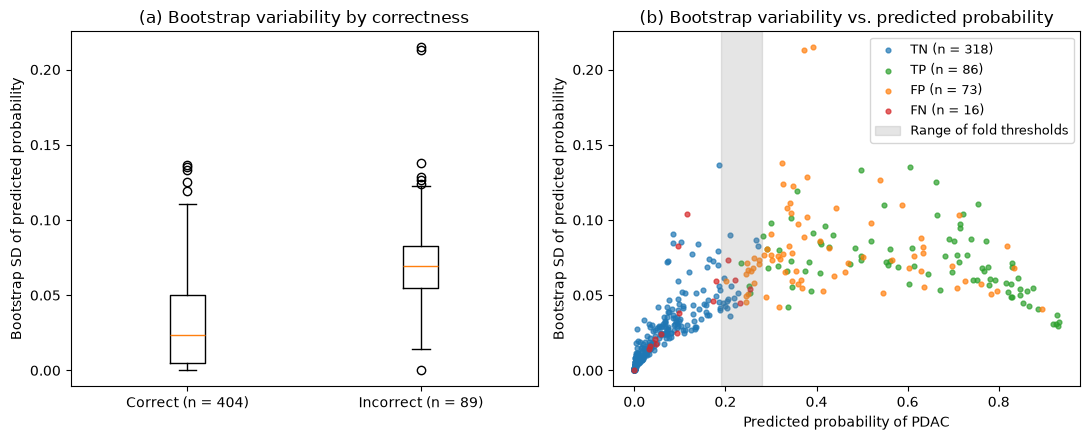

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# (a) bootstrap SD: correct vs. wrong
axes[0].boxplot([sd_right, sd_wrong], showfliers=True)
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels([f"Correct (n = {len(sd_right)})", f"Incorrect (n = {len(sd_wrong)})"])
axes[0].set_ylabel("Bootstrap SD of predicted probability")
axes[0].set_title("(a) Bootstrap variability by correctness")

# (b) bootstrap SD vs. predicted probability, colored by TP/FP/TN/FN
for outcome, color in zip(["TN", "TP", "FP", "FN"], ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    sub = results[results["outcome"] == outcome]
    axes[1].scatter(sub["p"], sub["boot_sd"], s=12, alpha=0.7, color=color, label=f"{outcome} (n = {len(sub)})")
# gray band = where the fold thresholds sit
axes[1].axvspan(results["threshold"].min(), results["threshold"].max(), color="gray", alpha=0.2,
                label="Range of fold thresholds")
axes[1].set_xlabel("Predicted probability of PDAC")
axes[1].set_ylabel("Bootstrap SD of predicted probability")
axes[1].set_title("(b) Bootstrap variability vs. predicted probability")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("figures/rq1_uncertainty_vs_errors.png", dpi=200)
plt.show()

### 8b. Flagging at the same proportion

For each flagging rate (0% to 50%), each method sets aside the same number of samples:
- **Bootstrap variability:** flag the samples with the **highest** `boot_sd`.
- **Distance to threshold:** flag the samples **closest** to the threshold.

Then we compute the **error rate among the unflagged predictions**. Lower is better. The dashed line is the overall error rate with no flagging.

In [20]:
n_total = len(results)
rows = []
for prop in FLAG_PROPORTIONS:
    n_flag = int(round(prop * n_total))   # same number flagged for both methods = fair comparison

    # order samples from most to least uncertain
    # bootstrap: biggest SD first | distance: smallest distance first
    rankings = {
        "Bootstrap variability": results.sort_values("boot_sd", ascending=False, kind="mergesort").index,
        "Distance to threshold": results.sort_values("dist_to_threshold", ascending=True, kind="mergesort").index,
    }
    for method, order in rankings.items():
        flagged = results.loc[order[:n_flag]]    # set aside for review
        kept = results.drop(order[:n_flag])      # predictions we'd still trust
        rows.append({
            "Method": method,
            "Proportion flagged": prop,
            "Number flagged": n_flag,
            "Error rate (unflagged)": kept["error"].mean(),     # flagged samples are NOT counted as correct
            "Errors caught": int(flagged["error"].sum()),
            "Cancers flagged": int(flagged["y"].sum()),
            "Non-cancers flagged": int((flagged["y"] == 0).sum()),
            "Flagged predicted as PDAC": int(flagged["pred"].sum()),
            "False negatives unflagged": int((kept["outcome"] == "FN").sum()),
            "False positives unflagged": int((kept["outcome"] == "FP").sum()),
        })

flag_df = pd.DataFrame(rows)
flag_df.to_csv("results/flagging_comparison.csv", index=False)

# unflagged error rate, both methods side by side
print(flag_df.pivot(index="Proportion flagged", columns="Method", values="Error rate (unflagged)").round(3))

Method              Bootstrap variability  Distance to threshold
Proportion flagged                                              
0.00                                0.181                  0.181
0.05                                0.158                  0.169
0.10                                0.153                  0.160
0.15                                0.134                  0.146
0.20                                0.114                  0.129
0.25                                0.097                  0.124
0.30                                0.070                  0.122
0.35                                0.053                  0.119
0.40                                0.034                  0.105
0.45                                0.026                  0.107
0.50                                0.028                  0.109


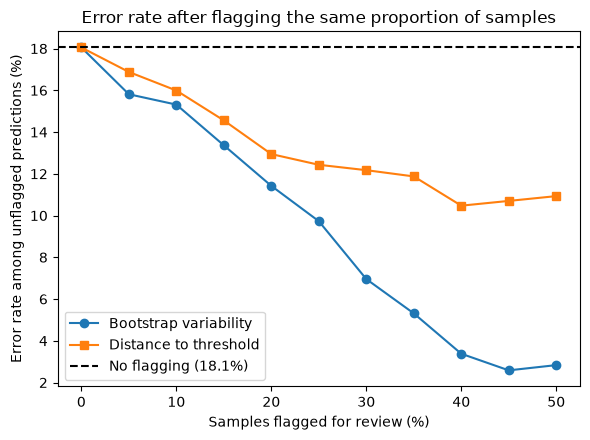

In [21]:
base_error = results["error"].mean()   # error rate if we flag nothing

# error rate among kept predictions as we flag more samples
fig, ax = plt.subplots(figsize=(6, 4.5))
for method, marker in zip(["Bootstrap variability", "Distance to threshold"], ["o", "s"]):
    sub = flag_df[flag_df["Method"] == method]
    ax.plot(sub["Proportion flagged"] * 100, sub["Error rate (unflagged)"] * 100, marker=marker, label=method)
ax.axhline(base_error * 100, color="k", linestyle="--", label=f"No flagging ({base_error:.1%})")
ax.set_xlabel("Samples flagged for review (%)")
ax.set_ylabel("Error rate among unflagged predictions (%)")
ax.set_title("Error rate after flagging the same proportion of samples")
ax.legend()
plt.tight_layout()
plt.savefig("figures/rq1_flagging_curves.png", dpi=200)
plt.show()

## Step 9: RQ2 — Is the effect strongest for benign disease?

**RQ2.** Is this effect strongest when distinguishing cancer from benign hepatobiliary disease, particularly chronic pancreatitis?

We compare error rates and bootstrap variability across groups:
- **Kruskal–Wallis test:** does bootstrap SD differ across control, benign and PDAC?
- **Mann–Whitney U test:** within benign disease, is bootstrap SD higher for chronic pancreatitis than for other benign conditions?

In [22]:
# split into 4 subgroups: control, chronic pancreatitis, other benign, early PDAC
results["subgroup"] = results["group"]
results.loc[results["chronic_pancreatitis"], "subgroup"] = "Chronic pancreatitis"
results.loc[(results["group"] == "Benign") & ~results["chronic_pancreatitis"], "subgroup"] = "Other benign"
subgroup_order = ["Control", "Chronic pancreatitis", "Other benign", "PDAC I-II"]

summary_rows = []
for sg in subgroup_order:
    sub = results[results["subgroup"] == sg]
    row = {"Subgroup": sg, "n": len(sub), "Errors": int(sub["error"].sum()),
           "Error rate": round(sub["error"].mean(), 3),
           "Median boot SD": round(sub["boot_sd"].median(), 4)}
    # error-detection AUROC inside the subgroup (only works if it has both right and wrong predictions)
    if sub["error"].nunique() == 2:
        row["Err-AUROC (boot SD)"] = round(roc_auc_score(sub["error"], sub["boot_sd"]), 3)
        row["Err-AUROC (distance)"] = round(roc_auc_score(sub["error"], -sub["dist_to_threshold"]), 3)
    summary_rows.append(row)

subgroup_summary = pd.DataFrame(summary_rows)
print("Errors are false positives in non-cancer subgroups and false negatives in PDAC.")
print(subgroup_summary.to_string(index=False))

Errors are false positives in non-cancer subgroups and false negatives in PDAC.
            Subgroup   n  Errors  Error rate  Median boot SD  Err-AUROC (boot SD)  Err-AUROC (distance)
             Control 183      17       0.093          0.0112                0.951                 0.720
Chronic pancreatitis 119      36       0.303          0.0350                0.946                 0.517
        Other benign  89      20       0.225          0.0251                0.979                 0.467
           PDAC I-II 102      16       0.157          0.0681                0.209                 0.841


In [23]:
# Kruskal-Wallis (lecture 11): rank-based test for 3+ groups -> does SD differ across control/benign/PDAC?
sd_by_group = [results.loc[results["group"] == g, "boot_sd"] for g in ["Control", "Benign", "PDAC I-II"]]
h_stat, p_kw = stats.kruskal(*sd_by_group)
print(f"Kruskal-Wallis across control / benign / PDAC: H = {h_stat:.1f}, p = {p_kw:.2g}")

# one-sided Mann-Whitney: is SD higher in chronic pancreatitis than in other benign?
sd_cp = results.loc[results["subgroup"] == "Chronic pancreatitis", "boot_sd"]
sd_other = results.loc[results["subgroup"] == "Other benign", "boot_sd"]
u_cp, p_cp = stats.mannwhitneyu(sd_cp, sd_other, alternative="greater")
print(f"Chronic pancreatitis (n = {len(sd_cp)}) vs. other benign (n = {len(sd_other)}): "
      f"U = {u_cp:.0f}, one-sided p = {p_cp:.2g}")

Kruskal-Wallis across control / benign / PDAC: H = 115.7, p = 7.7e-26
Chronic pancreatitis (n = 119) vs. other benign (n = 89): U = 6201, one-sided p = 0.018


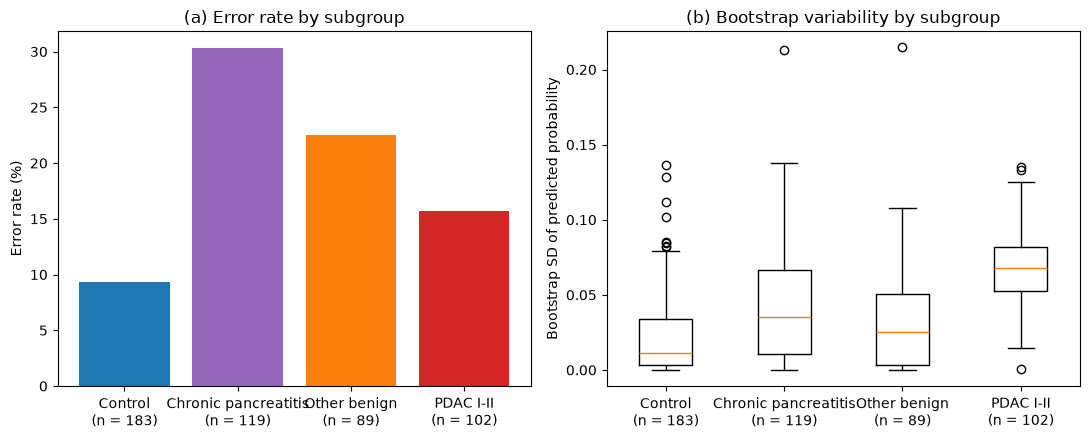

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = [f"{sg}\n(n = {(results['subgroup'] == sg).sum()})" for sg in subgroup_order]

# (a) error rate per subgroup
axes[0].bar(labels, subgroup_summary["Error rate"] * 100, color=["tab:blue", "tab:purple", "tab:orange", "tab:red"])
axes[0].set_ylabel("Error rate (%)")
axes[0].set_title("(a) Error rate by subgroup")

# (b) bootstrap SD per subgroup
axes[1].boxplot([results.loc[results["subgroup"] == sg, "boot_sd"] for sg in subgroup_order])
axes[1].set_xticks(range(1, 5))
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Bootstrap SD of predicted probability")
axes[1].set_title("(b) Bootstrap variability by subgroup")

plt.tight_layout()
plt.savefig("figures/rq2_groups.png", dpi=200)
plt.show()

## Step 10: RQ3 — What does each flagging approach cost?

**RQ3.** What does each flagging approach cost in practice, measured by the number of cancer cases sent for further review and the number of false negatives that remain unflagged?

A lower error rate is only useful if we can see what it costs: flagged cancers need extra follow-up, and any **false negatives left unflagged** are missed cancers.

In [25]:
# the "price" of flagging at a few example levels (from the Step 8b table)
cost_cols = ["Method", "Proportion flagged", "Number flagged", "Errors caught", "Cancers flagged",
             "Non-cancers flagged", "False negatives unflagged", "False positives unflagged"]
example_props = [0.10, 0.20, 0.30, 0.50]
print(f"Total cancers: {int(results['y'].sum())}, false negatives with no flagging: {(results['outcome'] == 'FN').sum()}")
print(flag_df.loc[flag_df["Proportion flagged"].isin(example_props), cost_cols].to_string(index=False))

Total cancers: 102, false negatives with no flagging: 16
               Method  Proportion flagged  Number flagged  Errors caught  Cancers flagged  Non-cancers flagged  False negatives unflagged  False positives unflagged
Bootstrap variability                 0.1              49             21               23                   26                         15                         53
Distance to threshold                 0.1              49             18                9                   40                         12                         59
Bootstrap variability                 0.2              99             44               44                   55                         13                         32
Distance to threshold                 0.2              99             38               20                   79                          9                         42
Bootstrap variability                 0.3             148             65               69                   79        

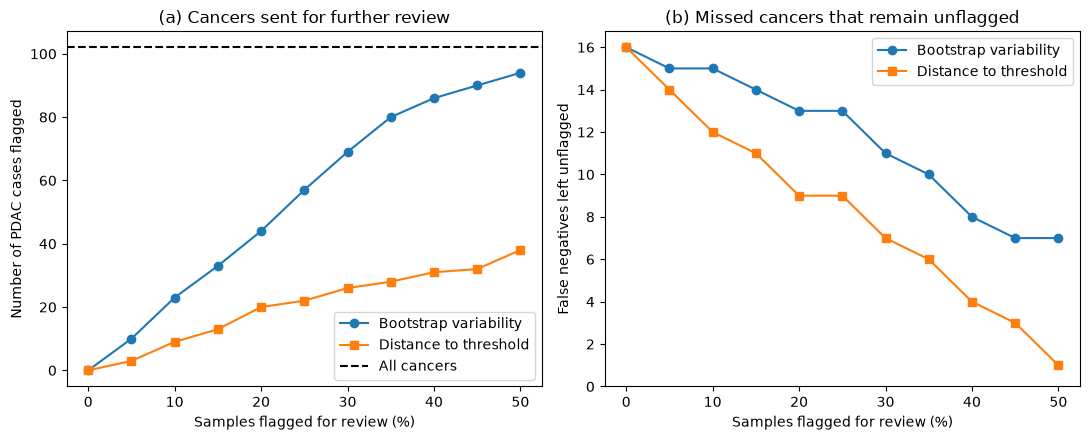

In [26]:
# (a) how many real cancers get sent for review, (b) how many missed cancers slip through
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for method, marker in zip(["Bootstrap variability", "Distance to threshold"], ["o", "s"]):
    sub = flag_df[flag_df["Method"] == method]
    axes[0].plot(sub["Proportion flagged"] * 100, sub["Cancers flagged"], marker=marker, label=method)
    axes[1].plot(sub["Proportion flagged"] * 100, sub["False negatives unflagged"], marker=marker, label=method)

axes[0].axhline(results["y"].sum(), color="k", linestyle="--", label="All cancers")
axes[0].set_xlabel("Samples flagged for review (%)")
axes[0].set_ylabel("Number of PDAC cases flagged")
axes[0].set_title("(a) Cancers sent for further review")
axes[0].legend()

axes[1].set_xlabel("Samples flagged for review (%)")
axes[1].set_ylabel("False negatives left unflagged")
axes[1].set_title("(b) Missed cancers that remain unflagged")
axes[1].set_ylim(bottom=0)
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/rq3_costs.png", dpi=200)
plt.show()

## Step 11: RQ4 — Calibration

**RQ4.** How well do the model's predicted probabilities agree with observed cancer frequencies within this dataset?

- **Calibration curve:** groups samples by predicted probability and compares the average prediction with the actual fraction of cancers in each group. A perfectly calibrated model follows the diagonal.
- **Brier score:** the mean squared difference between predicted probability and the true outcome (lower is better).

This dataset is a case–control study, so the share of cancers (about 21%) is much higher than in the general population. Calibration here only applies within this dataset.

 Mean predicted probability  Observed PDAC fraction
                      0.000                   0.016
                      0.002                   0.000
                      0.017                   0.016
                      0.056                   0.065
                      0.119                   0.098
                      0.252                   0.210
                      0.442                   0.508
                      0.767                   0.742

Brier score = 0.095
For reference, always predicting the cancer share (0.207) gives a Brier score of 0.164


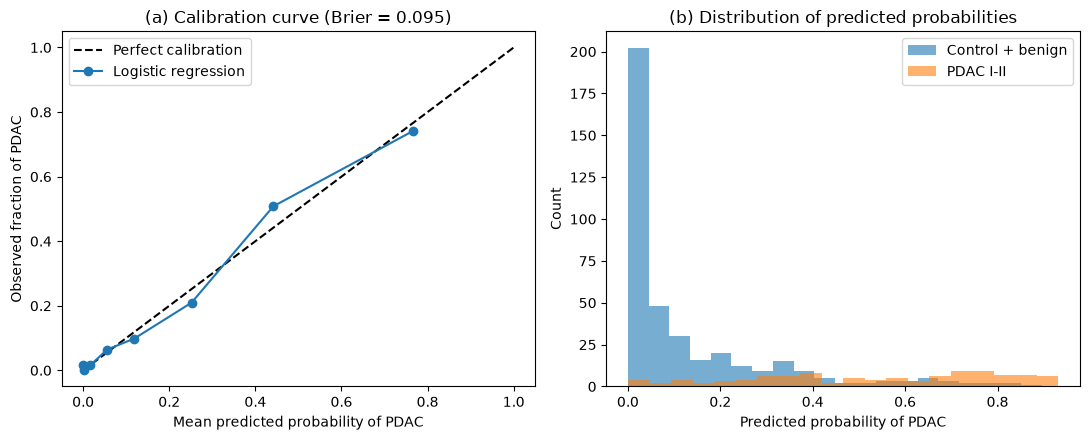

In [ ]:
# calibration curve ( as in lecture 17): 8 equal-count bins, predicted vs. observed cancer rate
frac_pos, mean_pred = calibration_curve(results["y"], results["p"], n_bins=8, strategy="quantile")
# Brier score = average squared gap between predicted probability and the true 0/1 (lower = better)
brier = np.mean((results["p"] - results["y"]) ** 2)

calib_table = pd.DataFrame({"Mean predicted probability": mean_pred.round(3),
                            "Observed PDAC fraction": frac_pos.round(3)})
print(calib_table.to_string(index=False))
print(f"\nBrier score = {brier:.3f}")
# baseline: a "model" that always guesses the cancer share
print(f"For reference, always predicting the cancer share ({results['y'].mean():.3f}) "
      f"gives a Brier score of {np.mean((results['y'].mean() - results['y']) ** 2):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
# (a) calibration curve - on the diagonal = well calibrated
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[0].plot(mean_pred, frac_pos, "o-", label="Logistic regression")
axes[0].set_xlabel("Mean predicted probability of PDAC")
axes[0].set_ylabel("Observed fraction of PDAC")
axes[0].set_title(f"(a) Calibration curve (Brier = {brier:.3f})")
axes[0].legend()

# (b) where the predicted probabilities fall for each class
axes[1].hist(results.loc[results["y"] == 0, "p"], bins=20, alpha=0.6, label="Control + benign")
axes[1].hist(results.loc[results["y"] == 1, "p"], bins=20, alpha=0.6, label="PDAC I-II")
axes[1].set_xlabel("Predicted probability of PDAC")
axes[1].set_ylabel("Count")
axes[1].set_title("(b) Distribution of predicted probabilities")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/rq4_calibration.png", dpi=200)
plt.show()

## Step 12: Summary of key results

In [ ]:
#helper to grab one number from the flagging table
def flag_value(method, prop, col):
    return flag_df.loc[(flag_df["Method"] == method) & (flag_df["Proportion flagged"] == prop), col].iloc[0]

# everything we report in the Results section, in one place
print("MODEL PERFORMANCE (mean ± SD over 5 held-out folds)")
for col in ["AUROC", "Sensitivity", "Specificity", "Balanced accuracy"]:
    print(f"  {col}: {fold_metrics[col].mean():.3f} ± {fold_metrics[col].std():.3f}")
print(f"  Pooled errors: {results['error'].sum()} of {len(results)} "
      f"({(results['outcome'] == 'FP').sum()} FP, {(results['outcome'] == 'FN').sum()} FN)")
print()
print("RQ1")
print(f"  Median boot SD, incorrect vs. correct: {sd_wrong.median():.4f} vs. {sd_right.median():.4f} (one-sided p = {p_mw:.2g})")
print(f"  Error-detection AUROC: bootstrap SD {auc_err_sd:.3f}, distance to threshold {auc_err_dist:.3f}")
print(f"  Spearman rho: SD vs. distance {rho_sd_dist:.2f}; SD vs. predicted probability {rho_sd_p:.2f}")
for prop in [0.10, 0.20, 0.30]:
    print(f"  Flag {prop:.0%}: unflagged error rate {flag_value('Bootstrap variability', prop, 'Error rate (unflagged)'):.1%} (bootstrap) "
          f"vs. {flag_value('Distance to threshold', prop, 'Error rate (unflagged)'):.1%} (distance); no flagging {base_error:.1%}")
print()
print("RQ2")
print(subgroup_summary.to_string(index=False))
print(f"  Kruskal-Wallis p = {p_kw:.2g}; chronic pancreatitis vs. other benign one-sided p = {p_cp:.2g}")
print()
print("RQ3 (at 20% flagged)")
for m in ["Bootstrap variability", "Distance to threshold"]:
    print(f"  {m}: {flag_value(m, 0.2, 'Cancers flagged')} cancers flagged, "
          f"{flag_value(m, 0.2, 'False negatives unflagged')} false negatives left unflagged")
print()
print("RQ4")
print(f"  Brier score = {brier:.3f}")

MODEL PERFORMANCE (mean ± SD over 5 held-out folds)
  AUROC: 0.904 ± 0.022
  Sensitivity: 0.841 ± 0.109
  Specificity: 0.813 ± 0.064
  Balanced accuracy: 0.827 ± 0.036
  Pooled errors: 89 of 493 (73 FP, 16 FN)

RQ1
  Median boot SD, incorrect vs. correct: 0.0692 vs. 0.0233 (one-sided p = 5.9e-23)
  Error-detection AUROC: bootstrap SD 0.831, distance to threshold 0.624
  Spearman rho: SD vs. distance -0.23; SD vs. predicted probability 0.91
  Flag 10%: unflagged error rate 15.3% (bootstrap) vs. 16.0% (distance); no flagging 18.1%
  Flag 20%: unflagged error rate 11.4% (bootstrap) vs. 12.9% (distance); no flagging 18.1%
  Flag 30%: unflagged error rate 7.0% (bootstrap) vs. 12.2% (distance); no flagging 18.1%

RQ2
            Subgroup   n  Errors  Error rate  Median boot SD  Err-AUROC (boot SD)  Err-AUROC (distance)
             Control 183      17       0.093          0.0112                0.951                 0.720
Chronic pancreatitis 119      36       0.303          0.0350           